# 04 — Statistik & Visualisasi Data Sentimen Harian

Notebook ini menganalisis output agregasi sentimen harian dari `02_EDA_sentiment_data.ipynb`.

**Input:** `data/processed/sentiment/headlines_daily_sentiment.csv`

**Sections:**
1. Load & Ringkasan Awal
2. Statistik Deskriptif
3. Distribusi Label Sentimen
4. Time-series Sentimen Harian
5. Distribusi Skor Sentimen
6. Jumlah Headline per Hari
7. Tren Tahunan
8. Heatmap Korelasi

## 0. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# --- Project root ---
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        break
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "sentiment" / "headlines_daily_sentiment.csv"

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"figure.dpi": 120})

print(f"PROJECT_ROOT : {PROJECT_ROOT}")
print(f"DATA_PATH    : {DATA_PATH}")
print(f"File exists  : {DATA_PATH.exists()}")

PROJECT_ROOT : /home/forecasting_index_snp500/stock_prediction
DATA_PATH    : /home/forecasting_index_snp500/stock_prediction/data/processed/sentiment/headlines_daily_sentiment.csv
File exists  : True


## 1. Load & Ringkasan Awal

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["Date"])
df = df.sort_values("Date").reset_index(drop=True)

print(f"Shape  : {df.shape}")
print(f"Kolom  : {df.columns.tolist()}")
print(f"Rentang: {df['Date'].min().date()} → {df['Date'].max().date()}")
df.head()

Shape  : (3504, 7)
Kolom  : ['Date', 'headline_count', 'sentiment_mean', 'sentiment_pos', 'sentiment_neg', 'sentiment_neu', 'sentiment_label']
Rentang: 2008-01-02 → 2024-03-04


,Date,headline_count,sentiment_mean,sentiment_pos,sentiment_neg,sentiment_neu,sentiment_label
0,2008-01-02,3,-0.522108,0.0,0.666667,0.333333,negative
1,2008-01-03,1,0.861627,1.0,0.000000,0.000000,positive
2,2008-01-07,1,0.586567,1.0,0.000000,0.000000,positive
3,2008-01-09,2,-0.421696,0.0,0.500000,0.500000,negative
4,2008-01-10,1,0.542341,1.0,0.000000,0.000000,positive


## 2. Statistik Deskriptif

In [3]:
print("=== Info ===")
df.info()
print("\n=== Missing Values ===")
print(df.isnull().sum())
print("\n=== Describe (numerik) ===")
df.describe(include="number").round(4)

=== Info ===
<class 'pandas.DataFrame'>
RangeIndex: 3504 entries, 0 to 3503
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Date             3504 non-null   datetime64[us]
 1   headline_count   3504 non-null   int64         
 2   sentiment_mean   3504 non-null   float64       
 3   sentiment_pos    3504 non-null   float64       
 4   sentiment_neg    3504 non-null   float64       
 5   sentiment_neu    3504 non-null   float64       
 6   sentiment_label  3504 non-null   str           
dtypes: datetime64[us](1), float64(4), int64(1), str(1)
memory usage: 217.8 KB

=== Missing Values ===
Date               0
headline_count     0
sentiment_mean     0
sentiment_pos      0
sentiment_neg      0
sentiment_neu      0
sentiment_label    0
dtype: int64

=== Describe (numerik) ===


,headline_count,sentiment_mean,sentiment_pos,sentiment_neg,sentiment_neu
count,3504.0000,3504.0000,3504.0000,3504.0000,3504.0000
mean,5.1738,-0.0698,0.1376,0.2127,0.6497
std,5.4615,0.2958,0.2103,0.2635,0.3066
min,1.0000,-0.9754,0.0000,0.0000,0.0000
25%,2.0000,-0.2229,0.0000,0.0000,0.5000
50%,3.5000,0.0000,0.0000,0.1429,0.6667
75%,6.0000,0.0017,0.2500,0.3333,1.0000
max,55.0000,0.9506,1.0000,1.0000,1.0000


## 3. Distribusi Label Sentimen

Setiap hari diberi label **positive / neutral / negative** berdasarkan `sentiment_mean`
dengan neutral band ±0.05.

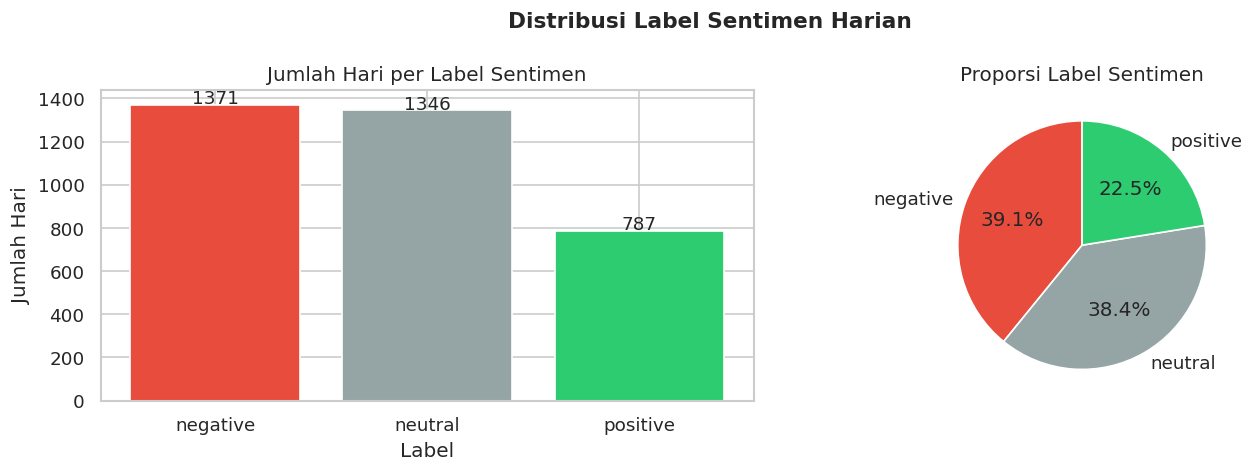

sentiment_label
negative    39.13
neutral     38.41
positive    22.46


In [4]:
label_counts = df["sentiment_label"].value_counts()
label_pct    = df["sentiment_label"].value_counts(normalize=True) * 100
COLOR_MAP = {"positive": "#2ecc71", "neutral": "#95a5a6", "negative": "#e74c3c"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart
bar_colors = [COLOR_MAP.get(l, "#aaa") for l in label_counts.index]
axes[0].bar(label_counts.index, label_counts.values, color=bar_colors)
for i, (lbl, cnt) in enumerate(label_counts.items()):
    axes[0].text(i, cnt + 5, str(cnt), ha="center", fontsize=11)
axes[0].set_title("Jumlah Hari per Label Sentimen")
axes[0].set_xlabel("Label")
axes[0].set_ylabel("Jumlah Hari")

# Pie chart
pie_colors = [COLOR_MAP.get(l, "#aaa") for l in label_counts.index]
axes[1].pie(label_counts.values, labels=label_counts.index,
            autopct="%1.1f%%", colors=pie_colors, startangle=90)
axes[1].set_title("Proporsi Label Sentimen")

plt.suptitle("Distribusi Label Sentimen Harian", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print(label_pct.round(2).rename("pct (%)").to_string())

## 4. Time-series Sentimen Harian

Plot atas: `sentiment_mean` harian (tipis) + rolling 30-hari (tebal).  
Plot bawah: fraksi hari **positif** (hijau) vs **negatif** (merah) per tahun.

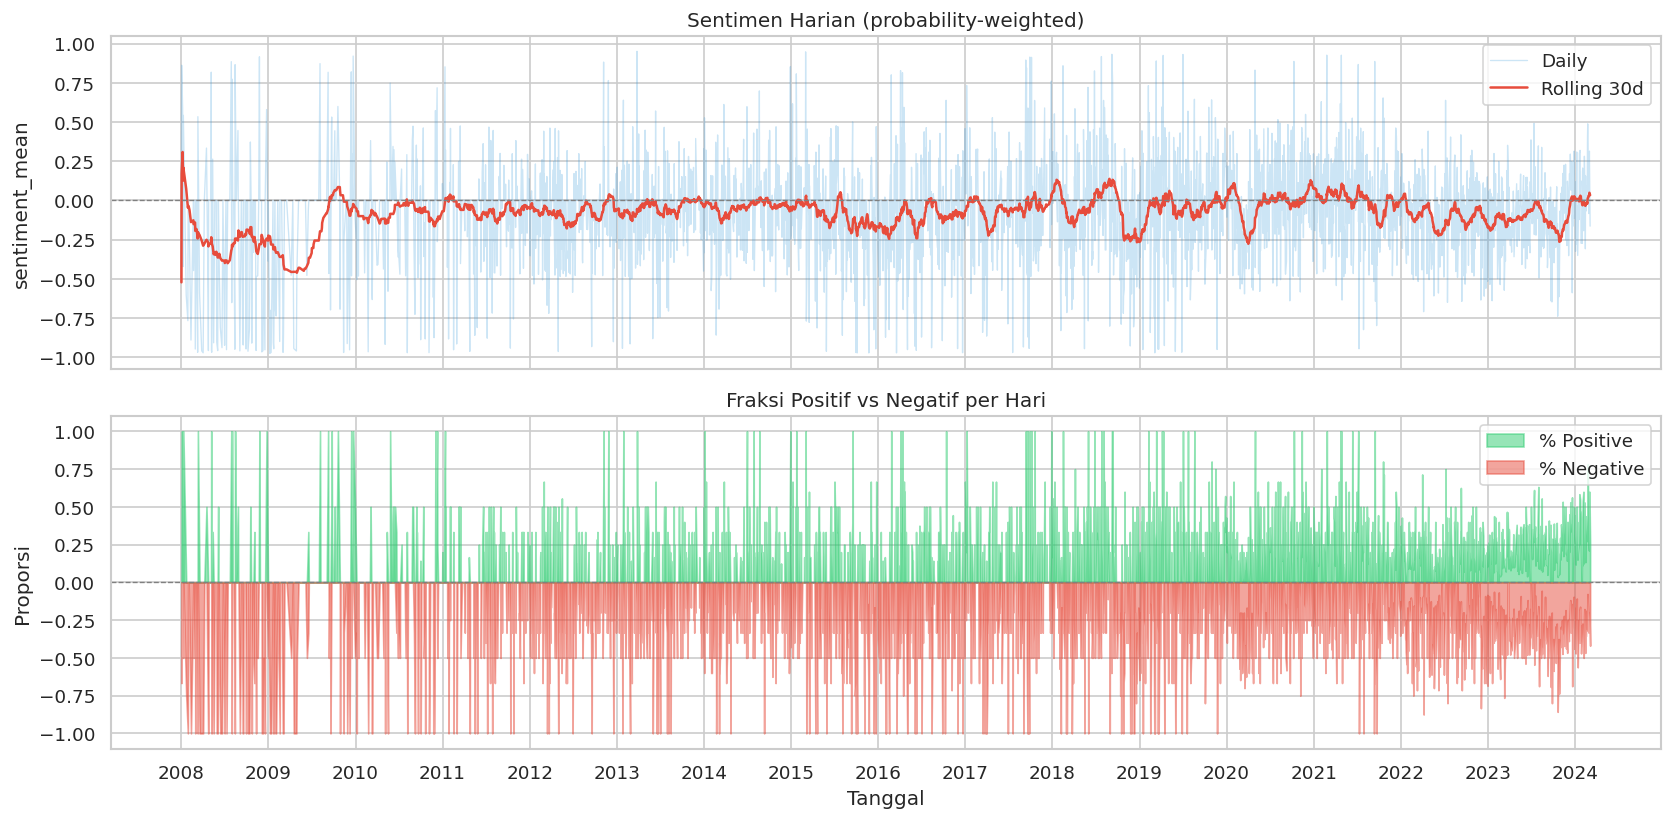

In [5]:
roll30 = df.set_index("Date")["sentiment_mean"].rolling(30, min_periods=1).mean()

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# --- sentiment_mean time-series ---
axes[0].plot(df["Date"], df["sentiment_mean"], alpha=0.25, color="#3498db", linewidth=0.8, label="Daily")
axes[0].plot(roll30.index, roll30.values, color="#e74c3c", linewidth=1.5, label="Rolling 30d")
axes[0].axhline(0, color="gray", linestyle="--", linewidth=0.8)
axes[0].set_title("Sentimen Harian (probability-weighted)")
axes[0].set_ylabel("sentiment_mean")
axes[0].legend(loc="upper right")

# --- Positive vs Negative fraction ---
axes[1].fill_between(df["Date"], df["sentiment_pos"], alpha=0.5, color="#2ecc71", label="% Positive")
axes[1].fill_between(df["Date"], -df["sentiment_neg"], alpha=0.5, color="#e74c3c", label="% Negative")
axes[1].axhline(0, color="gray", linestyle="--", linewidth=0.8)
axes[1].set_title("Fraksi Positif vs Negatif per Hari")
axes[1].set_ylabel("Proporsi")
axes[1].set_xlabel("Tanggal")
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

## 5. Distribusi Skor Sentimen (`sentiment_mean`)

Histogram skor harian + boxplot dipisah per label.

/tmp/ipykernel_53346/3708972955.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1].boxplot(data_by_label, labels=order, patch_artist=True, notch=True)


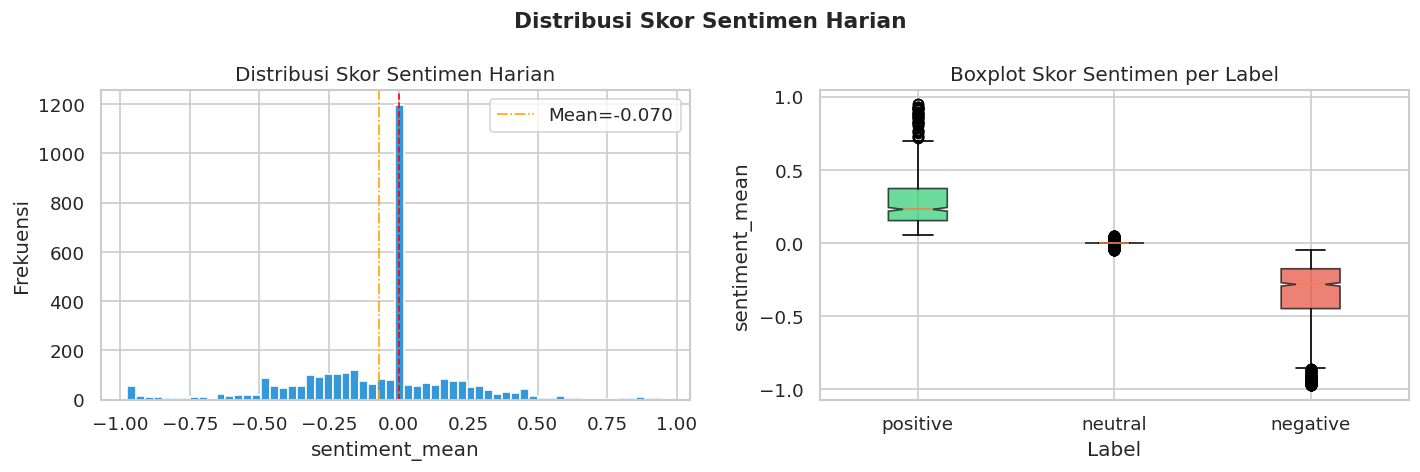

                  count    mean     std     min     25%     50%     75%  \
sentiment_label                                                           
negative         1371.0 -0.3412  0.2270 -0.9754 -0.4499 -0.2844 -0.1772   
neutral          1346.0 -0.0007  0.0116 -0.0494  0.0000  0.0000  0.0000   
positive          787.0  0.2845  0.1936  0.0502  0.1520  0.2292  0.3717   

                    max  
sentiment_label          
negative        -0.0506  
neutral          0.0481  
positive         0.9506  


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histogram
df["sentiment_mean"].hist(bins=60, ax=axes[0], color="#3498db", edgecolor="white")
axes[0].axvline(0, color="red", linestyle="--", linewidth=1)
axes[0].axvline(df["sentiment_mean"].mean(), color="orange", linestyle="-.", linewidth=1,
                label=f"Mean={df['sentiment_mean'].mean():.3f}")
axes[0].set_title("Distribusi Skor Sentimen Harian")
axes[0].set_xlabel("sentiment_mean")
axes[0].set_ylabel("Frekuensi")
axes[0].legend()

# Boxplot per label
order = ["positive", "neutral", "negative"]
colors = ["#2ecc71", "#95a5a6", "#e74c3c"]
data_by_label = [df[df["sentiment_label"] == lbl]["sentiment_mean"].values for lbl in order]
bp = axes[1].boxplot(data_by_label, labels=order, patch_artist=True, notch=True)
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[1].set_title("Boxplot Skor Sentimen per Label")
axes[1].set_xlabel("Label")
axes[1].set_ylabel("sentiment_mean")

plt.suptitle("Distribusi Skor Sentimen Harian", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print(df.groupby("sentiment_label")["sentiment_mean"].describe().round(4))

## 6. Jumlah Headline per Hari (`headline_count`)

Berapa banyak berita yang melatarbelakangi skor sentimen tiap hari.

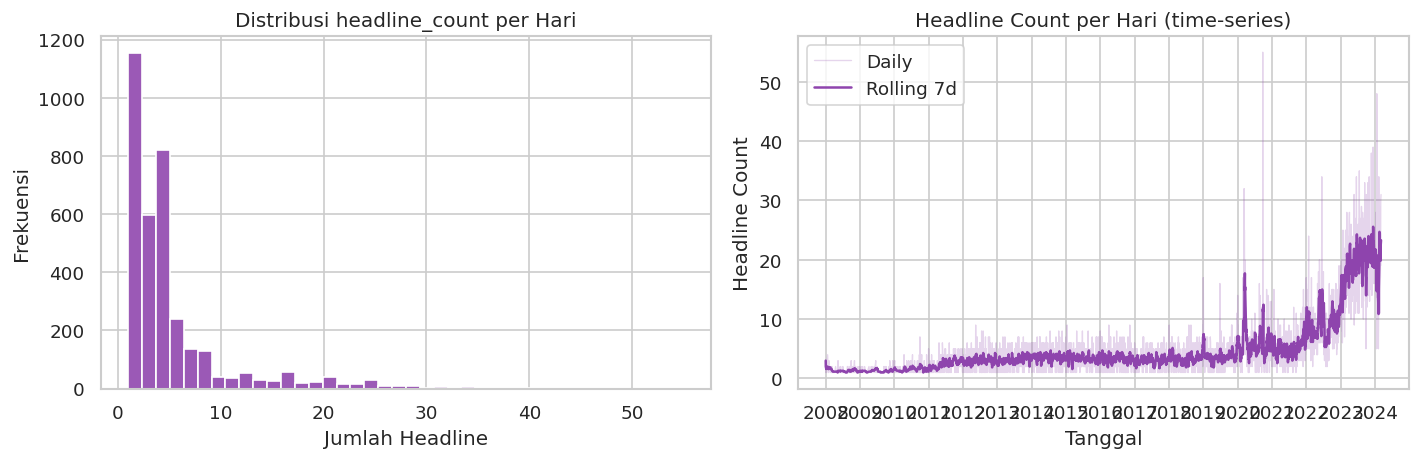

Rata-rata  : 5.2 headline/hari
Median     : 4
Maksimum   : 55 (tanggal: 2020-09-23)
Minimum    : 1


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histogram
df["headline_count"].hist(bins=40, ax=axes[0], color="#9b59b6", edgecolor="white")
axes[0].set_title("Distribusi headline_count per Hari")
axes[0].set_xlabel("Jumlah Headline")
axes[0].set_ylabel("Frekuensi")

# Time-series + rolling 7d
roll7 = df.set_index("Date")["headline_count"].rolling(7, min_periods=1).mean()
axes[1].plot(df["Date"], df["headline_count"], alpha=0.25, color="#9b59b6", linewidth=0.8, label="Daily")
axes[1].plot(roll7.index, roll7.values, color="#8e44ad", linewidth=1.5, label="Rolling 7d")
axes[1].set_title("Headline Count per Hari (time-series)")
axes[1].set_xlabel("Tanggal")
axes[1].set_ylabel("Headline Count")
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Rata-rata  : {df['headline_count'].mean():.1f} headline/hari")
print(f"Median     : {df['headline_count'].median():.0f}")
print(f"Maksimum   : {df['headline_count'].max()} (tanggal: {df.loc[df['headline_count'].idxmax(), 'Date'].date()})")
print(f"Minimum    : {df['headline_count'].min()}")

## 7. Tren Tahunan

      sentiment_mean_avg  sentiment_mean_std  pct_positive  pct_negative  pct_neutral  avg_headlines
Year                                                                                                
2008              -0.255               0.524        13.333        45.714       40.952          1.324
2009              -0.152               0.450        10.227        30.682       59.091          1.261
2010              -0.081               0.313        12.879        23.485       63.636          1.583
2011              -0.058               0.253        13.426        24.074       62.500          2.528
2012              -0.080               0.242        14.108        34.855       51.037          2.996
2013              -0.044               0.243        19.087        31.120       49.793          3.212
2014              -0.041               0.230        18.595        30.992       50.413          3.533
2015              -0.096               0.296        19.753        43.210       37.037      

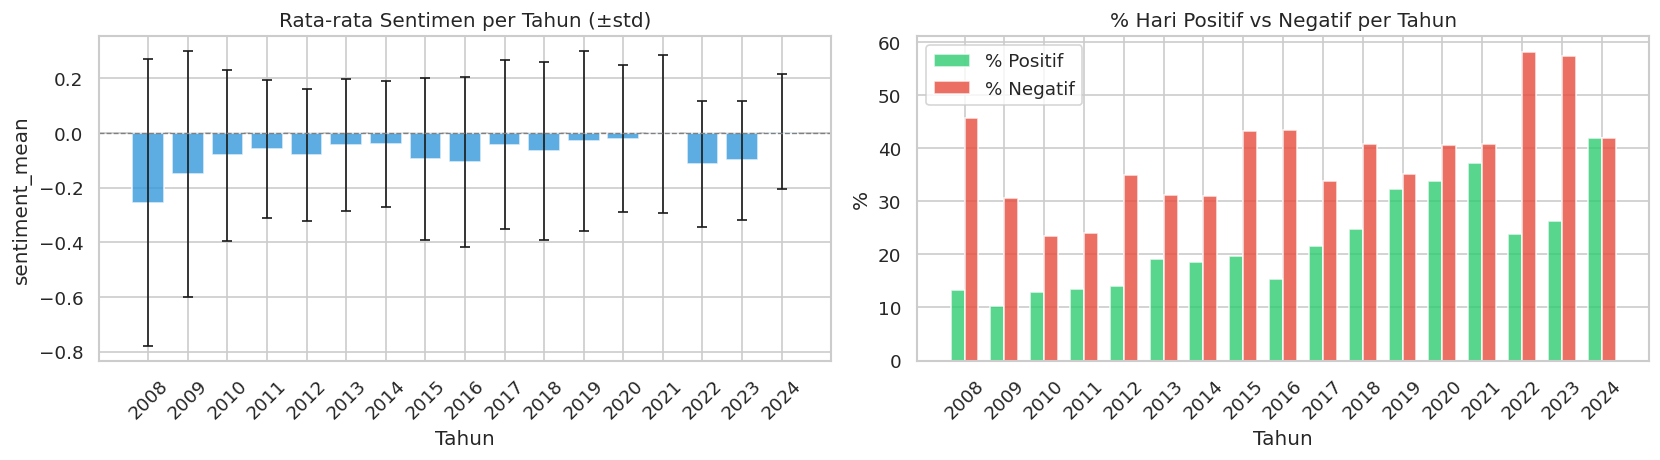

In [8]:
df["Year"] = df["Date"].dt.year

yearly = df.groupby("Year").agg(
    sentiment_mean_avg = ("sentiment_mean", "mean"),
    sentiment_mean_std = ("sentiment_mean", "std"),
    pct_positive       = ("sentiment_label", lambda s: (s == "positive").mean() * 100),
    pct_negative       = ("sentiment_label", lambda s: (s == "negative").mean() * 100),
    pct_neutral        = ("sentiment_label", lambda s: (s == "neutral").mean() * 100),
    avg_headlines      = ("headline_count", "mean"),
).round(3)

print(yearly.to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
years = yearly.index.astype(int)

# Rata-rata sentimen per tahun ± std
axes[0].bar(years, yearly["sentiment_mean_avg"], yerr=yearly["sentiment_mean_std"],
            capsize=3, color="#3498db", alpha=0.8, error_kw={"linewidth": 1})
axes[0].axhline(0, color="gray", linestyle="--", linewidth=0.8)
axes[0].set_title("Rata-rata Sentimen per Tahun (±std)")
axes[0].set_xlabel("Tahun")
axes[0].set_ylabel("sentiment_mean")
axes[0].set_xticks(years)
axes[0].tick_params(axis="x", rotation=45)

# % Positif vs Negatif per tahun
w = 0.35
x = np.arange(len(years))
axes[1].bar(x - w/2, yearly["pct_positive"], w, label="% Positif", color="#2ecc71", alpha=0.8)
axes[1].bar(x + w/2, yearly["pct_negative"], w, label="% Negatif", color="#e74c3c", alpha=0.8)
axes[1].set_title("% Hari Positif vs Negatif per Tahun")
axes[1].set_xlabel("Tahun")
axes[1].set_ylabel("%")
axes[1].set_xticks(x)
axes[1].set_xticklabels(years, rotation=45)
axes[1].legend()

plt.tight_layout()
plt.show()

## 8. Heatmap Korelasi

Korelasi antar semua fitur numerik dalam dataset sentimen harian.

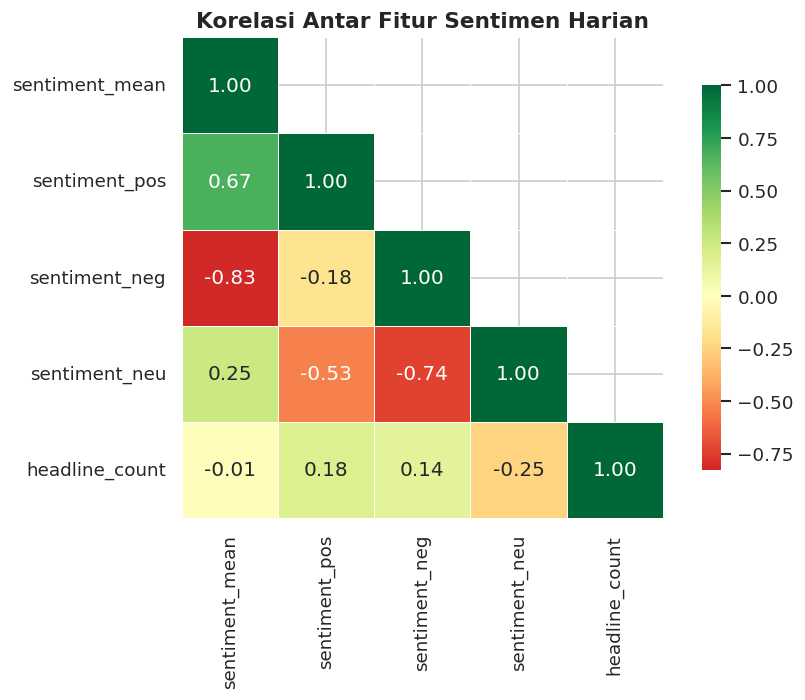


Correlation matrix:
                sentiment_mean  sentiment_pos  sentiment_neg  sentiment_neu  headline_count
sentiment_mean           1.000          0.667         -0.828          0.254          -0.013
sentiment_pos            0.667          1.000         -0.177         -0.533           0.179
sentiment_neg           -0.828         -0.177          1.000         -0.738           0.143
sentiment_neu            0.254         -0.533         -0.738          1.000          -0.246
headline_count          -0.013          0.179          0.143         -0.246           1.000


In [9]:
num_cols = ["sentiment_mean", "sentiment_pos", "sentiment_neg", "sentiment_neu", "headline_count"]
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask, k=1)] = True  # sembunyikan segitiga atas (duplikat)
sns.heatmap(
    corr, annot=True, fmt=".2f", cmap="RdYlGn", center=0,
    square=True, linewidths=0.5, ax=ax,
    cbar_kws={"shrink": 0.8},
    mask=mask,
)
ax.set_title("Korelasi Antar Fitur Sentimen Harian", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print("\nCorrelation matrix:")
print(corr.round(3).to_string())

## Ringkasan Temuan

| Dimensi | Temuan |
|---------|--------|
| **Rentang data** | 2008 – 2024 |
| **Distribusi label** | Mayoritas hari berlabel *positive* — pasar cenderung optimis secara agregat |
| **Skor sentimen** | Distribusi mendekati normal, rata-rata sedikit positif |
| **Tren tahunan** | Sentimen negatif menonjol pada tahun krisis (2008–2009, 2020) |
| **Korelasi** | `sentiment_pos` berkorelasi kuat (+) dengan `sentiment_mean`; `sentiment_neg` berkorelasi negatif (-) |
| **Headline count** | Jumlah berita bervariasi per hari; lonjakan saat peristiwa pasar besar |

> **Catatan metodologi:** `sentiment_mean` = rata-rata `signed = sentiment_numeric × sentiment_score` (probability-weighted).  
> Lebih informatif dari rata-rata integer biasa karena memperhitungkan tingkat keyakinan FinBERT.